In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Usuario\Python_Machine_Learning_Project\Datos\WA_Fn-UseC_-Telco-Customer-Churn_new_ad.csv")

display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(f"El dataset consta de {df.shape[0]} filas y {df.shape[1]} columnas")

El dataset consta de 10323 filas y 21 columnas


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10323 entries, 0 to 10322
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        10323 non-null  object 
 1   gender            10323 non-null  object 
 2   SeniorCitizen     10323 non-null  int64  
 3   Partner           10323 non-null  object 
 4   Dependents        10323 non-null  object 
 5   tenure            10323 non-null  int64  
 6   PhoneService      10323 non-null  object 
 7   MultipleLines     10323 non-null  object 
 8   InternetService   10323 non-null  object 
 9   OnlineSecurity    10323 non-null  object 
 10  OnlineBackup      10323 non-null  object 
 11  DeviceProtection  10323 non-null  object 
 12  TechSupport       10323 non-null  object 
 13  StreamingTV       10323 non-null  object 
 14  StreamingMovies   10323 non-null  object 
 15  Contract          10323 non-null  object 
 16  PaperlessBilling  10323 non-null  object

In [5]:
df.rename(columns={'customerID': 'CustomerID', 'gender': 'Gender', 'tenure': 'Tenure'}, inplace=True)

In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
df.isnull().sum()

CustomerID           0
Gender               0
SeniorCitizen        0
Partner              0
Dependents           0
Tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        44
Churn                0
dtype: int64

In [8]:
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10323 entries, 0 to 10322
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        10323 non-null  object 
 1   Gender            10323 non-null  object 
 2   SeniorCitizen     10323 non-null  int64  
 3   Partner           10323 non-null  object 
 4   Dependents        10323 non-null  object 
 5   Tenure            10323 non-null  int64  
 6   PhoneService      10323 non-null  object 
 7   MultipleLines     10323 non-null  object 
 8   InternetService   10323 non-null  object 
 9   OnlineSecurity    10323 non-null  object 
 10  OnlineBackup      10323 non-null  object 
 11  DeviceProtection  10323 non-null  object 
 12  TechSupport       10323 non-null  object 
 13  StreamingTV       10323 non-null  object 
 14  StreamingMovies   10323 non-null  object 
 15  Contract          10323 non-null  object 
 16  PaperlessBilling  10323 non-null  object

In [10]:
print(f"Número de registros duplicados: {df.duplicated().sum()}")

Número de registros duplicados: 4


In [11]:
df.drop_duplicates(inplace=True, ignore_index=True)

In [12]:
print(df.shape)

(10319, 21)


In [13]:
df.nunique()

CustomerID          10310
Gender                  2
SeniorCitizen           2
Partner                 2
Dependents              2
Tenure                 73
PhoneService            2
MultipleLines           3
InternetService         3
OnlineSecurity          3
OnlineBackup            3
DeviceProtection        3
TechSupport             3
StreamingTV             3
StreamingMovies         3
Contract                3
PaperlessBilling        2
PaymentMethod           4
MonthlyCharges       1585
TotalCharges         6530
Churn                   2
dtype: int64

In [13]:
display(df[df.duplicated(subset='customerID', keep=False)])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
345,0021-IKXGC,Female,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,72.10,72.10,No
689,5076-YVXCM,Male,0,No,No,51,Yes,Yes,Fiber optic,No,...,No,No,No,Yes,Month-to-month,No,Bank transfer (automatic),83.40,4149.45,No
6033,6595-YGXIT,Male,1,No,No,25,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,88.95,2291.20,Yes
6103,8573-CGOCC,Male,0,No,No,16,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Credit card (automatic),19.75,294.90,No
6264,2578-JQPHZ,Male,0,No,No,44,Yes,No,Fiber optic,No,...,Yes,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),100.10,4378.35,No
6615,8344-WFMFH,Male,0,No,Yes,9,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,50.10,484.05,No
6763,7471-MQPOS,Male,1,Yes,Yes,71,Yes,Yes,DSL,No,...,Yes,Yes,No,Yes,One year,Yes,Bank transfer (automatic),72.90,5139.65,No
6823,7009-LGECI,Female,0,No,No,4,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),50.55,235.65,No
7045,3286-AJISD,Female,1,No,No,13,Yes,No,Fiber optic,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7330,3286-AJISD,Male,0,Yes,No,17,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Electronic check,70.00,70.00,Yes


In [14]:
display(df[df.duplicated(subset='CustomerID', keep=False)])

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
345,0021-IKXGC,Female,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,72.10,72.10,No
689,5076-YVXCM,Male,0,No,No,51,Yes,Yes,Fiber optic,No,...,No,No,No,Yes,Month-to-month,No,Bank transfer (automatic),83.40,4149.45,No
6033,6595-YGXIT,Male,1,No,No,25,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,88.95,2291.20,Yes
6103,8573-CGOCC,Male,0,No,No,16,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Credit card (automatic),19.75,294.90,No
6264,2578-JQPHZ,Male,0,No,No,44,Yes,No,Fiber optic,No,...,Yes,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),100.10,4378.35,No
6615,8344-WFMFH,Male,0,No,Yes,9,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,50.10,484.05,No
6763,7471-MQPOS,Male,1,Yes,Yes,71,Yes,Yes,DSL,No,...,Yes,Yes,No,Yes,One year,Yes,Bank transfer (automatic),72.90,5139.65,No
6823,7009-LGECI,Female,0,No,No,4,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),50.55,235.65,No
7045,3286-AJISD,Female,1,No,No,13,Yes,No,Fiber optic,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7330,3286-AJISD,Male,0,Yes,No,17,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Electronic check,70.00,70.00,Yes


In [14]:
df['MonthlyChargesPerTenure'] = df['TotalCharges'] / (df['tenure'] + 1)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10319 entries, 0 to 10318
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerID               10319 non-null  object 
 1   gender                   10319 non-null  object 
 2   SeniorCitizen            10319 non-null  int64  
 3   Partner                  10319 non-null  object 
 4   Dependents               10319 non-null  object 
 5   tenure                   10319 non-null  int64  
 6   PhoneService             10319 non-null  object 
 7   MultipleLines            10319 non-null  object 
 8   InternetService          10319 non-null  object 
 9   OnlineSecurity           10319 non-null  object 
 10  OnlineBackup             10319 non-null  object 
 11  DeviceProtection         10319 non-null  object 
 12  TechSupport              10319 non-null  object 
 13  StreamingTV              10319 non-null  object 
 14  StreamingMovies       

In [16]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MonthlyChargesPerTenure
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,14.925000
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,53.985714
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,36.050000
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,40.016304
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,50.550000


In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,MonthlyChargesPerTenure
count,10319.000000,10319.000000,10319.000000,10319.000000,10319.000000
mean,0.203024,32.277934,64.814372,2275.686588,117.422707
std,0.402269,24.573905,30.112132,2260.670514,322.829331
min,0.000000,0.000000,18.250000,18.800000,0.264384
25%,0.000000,9.000000,35.450000,403.775000,24.114775
50%,0.000000,29.000000,70.400000,1391.150000,60.740000
75%,0.000000,55.000000,89.900000,3777.150000,91.461477
max,1.000000,72.000000,118.750000,8684.800000,8333.950000


In [18]:
df.select_dtypes(include='number').dtypes

SeniorCitizen                int64
tenure                       int64
MonthlyCharges             float64
TotalCharges               float64
MonthlyChargesPerTenure    float64
dtype: object

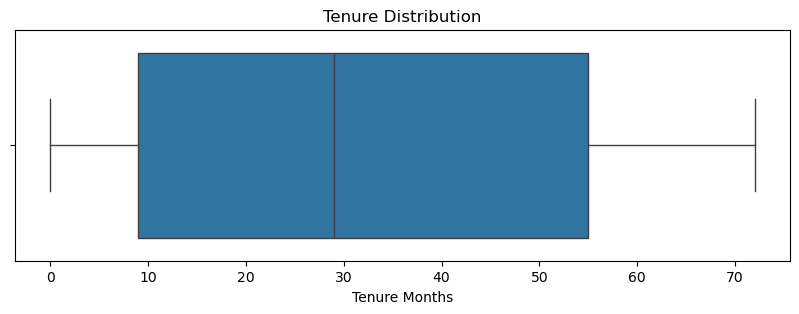

In [19]:
plt.figure(figsize=(10,3))
sns.boxplot(data=df, x='tenure', linewidth=1.0)
plt.title("Tenure Distribution")
plt.xlabel("Tenure Months")
plt.show()

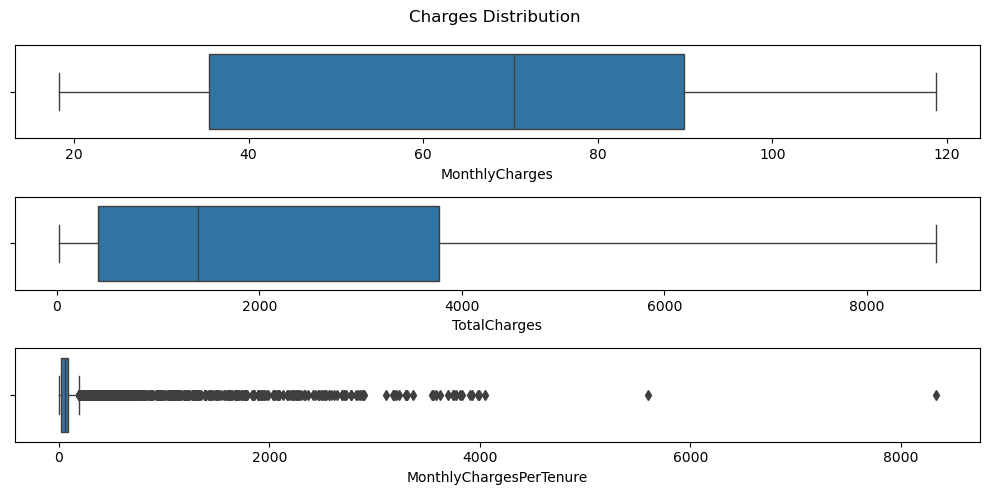

In [20]:
fig, ax = plt.subplots(nrows=3, figsize=(10,5))
fig.suptitle("Charges Distribution")

for i, column in enumerate(df.select_dtypes(include='float64').columns):
    sns.boxplot(data=df, x=column, ax=ax[i], linewidth=1.0)

plt.tight_layout()
plt.show()

In [21]:
for column in df.select_dtypes(include='number').drop(columns='SeniorCitizen').columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    threshold = 1.5
    print(f"Recuento de outliers inferiores en la columna {column}: {df[df[column] < Q1 - threshold * IQR][column].count()}")
    print(f"Recuento de outliers superiores en la columna {column}: {df[df[column] > Q3 + threshold * IQR][column].count()}")

Recuento de outliers inferiores en la columna tenure: 0
Recuento de outliers superiores en la columna tenure: 0
Recuento de outliers inferiores en la columna MonthlyCharges: 0
Recuento de outliers superiores en la columna MonthlyCharges: 0
Recuento de outliers inferiores en la columna TotalCharges: 0
Recuento de outliers superiores en la columna TotalCharges: 0
Recuento de outliers inferiores en la columna MonthlyChargesPerTenure: 0
Recuento de outliers superiores en la columna MonthlyChargesPerTenure: 757


c:\Users\Usuario\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Usuario\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Usuario\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Usuario\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before o

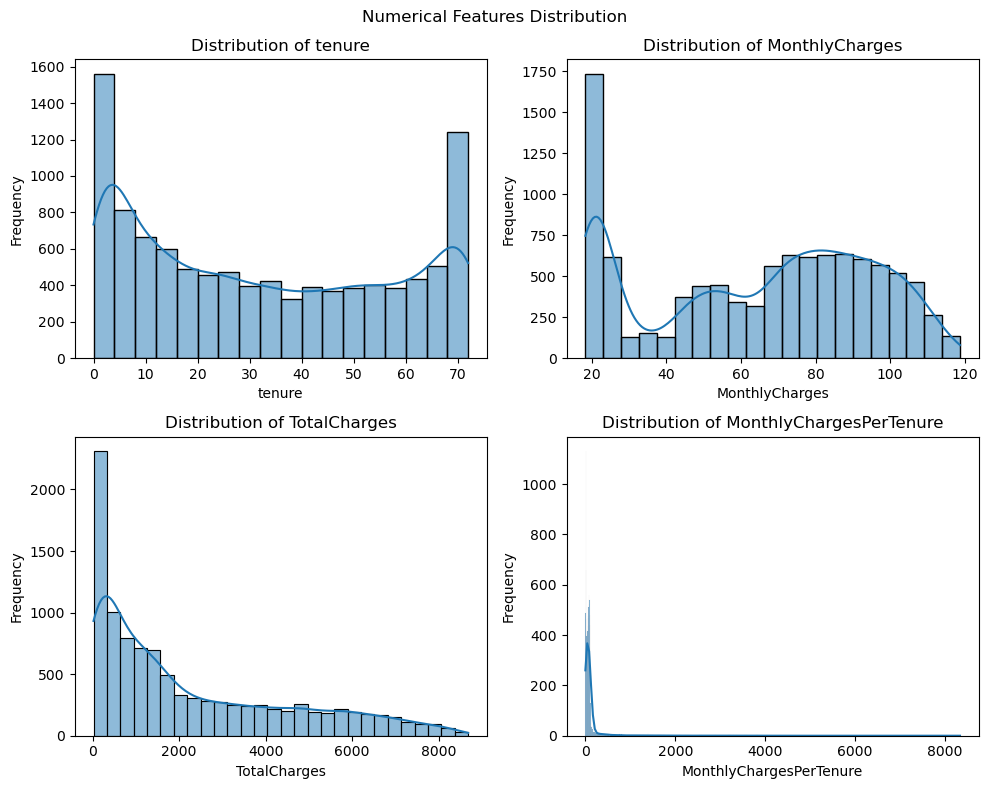

In [22]:
fig = plt.figure(figsize=(10,8))
fig.suptitle("Numerical Features Distribution")

for index, column in enumerate(df.select_dtypes(include='number').drop(columns='SeniorCitizen').columns, start=1):
    ax = fig.add_subplot(2, 2, index)
    sns.histplot(data=df, x=column, ax=ax, kde=True)
    ax.set_title(f"Distribution of {column}")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [23]:
for column in df.select_dtypes(include='object').drop(columns='customerID').columns:
    print(f"Recuento de valores de la columna {column}")
    display(df[column].value_counts())

Recuento de valores de la columna gender


gender
Male      5242
Female    5077
Name: count, dtype: int64

Recuento de valores de la columna Partner


Partner
No     5361
Yes    4958
Name: count, dtype: int64

Recuento de valores de la columna Dependents


Dependents
No     6620
Yes    3699
Name: count, dtype: int64

... (22 outputs left out)

Recuento de valores de la columna PaymentMethod


PaymentMethod
Electronic check             3452
Mailed check                 2348
Bank transfer (automatic)    2281
Credit card (automatic)      2238
Name: count, dtype: int64

Recuento de valores de la columna Churn


Churn
No     7595
Yes    2724
Name: count, dtype: int64

In [24]:
display(df[(df['PhoneService'] == 'No') & (df['MultipleLines'] != 'No phone service')])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MonthlyChargesPerTenure
7046,1291-MQJSD,Male,0,No,No,49,No,Yes,Fiber optic,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,36.815000
7063,3259-KNMSD,Female,1,No,No,72,No,No,DSL,No,...,No,No,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,Yes,0.543151
7070,1296-OQSSD,Male,0,Yes,Yes,10,No,No,DSL,No,...,No,No,No,Month-to-month,No,Electronic check,30.20,30.20,Yes,2.745455
7105,4207-MAXSD,Female,0,Yes,Yes,68,No,No,DSL,Yes,...,No,No,No,Two year,No,Bank transfer (automatic),42.10,2962.00,No,42.927536
7124,5268-YWPSD,Female,0,Yes,Yes,7,No,No,DSL,Yes,...,No,Yes,Yes,Month-to-month,No,Electronic check,50.55,565.35,No,70.668750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10267,6042-QZXPP,Female,0,No,Yes,45,No,Yes,DSL,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,74.65,521.10,Yes,11.328261
10277,9748-OGXQZ,Female,1,No,Yes,64,No,No,DSL,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,452.55,No,6.962308
10279,6047-TCXST,Male,1,No,No,62,No,No,DSL,No,...,No,No,No,Month-to-month,No,Electronic check,55.30,875.35,No,13.894444
10287,3244-DFXNQ,Male,1,No,No,72,No,No,Fiber optic,Yes,...,No,No,No,Month-to-month,Yes,Credit card (automatic),54.50,568.20,No,7.783562


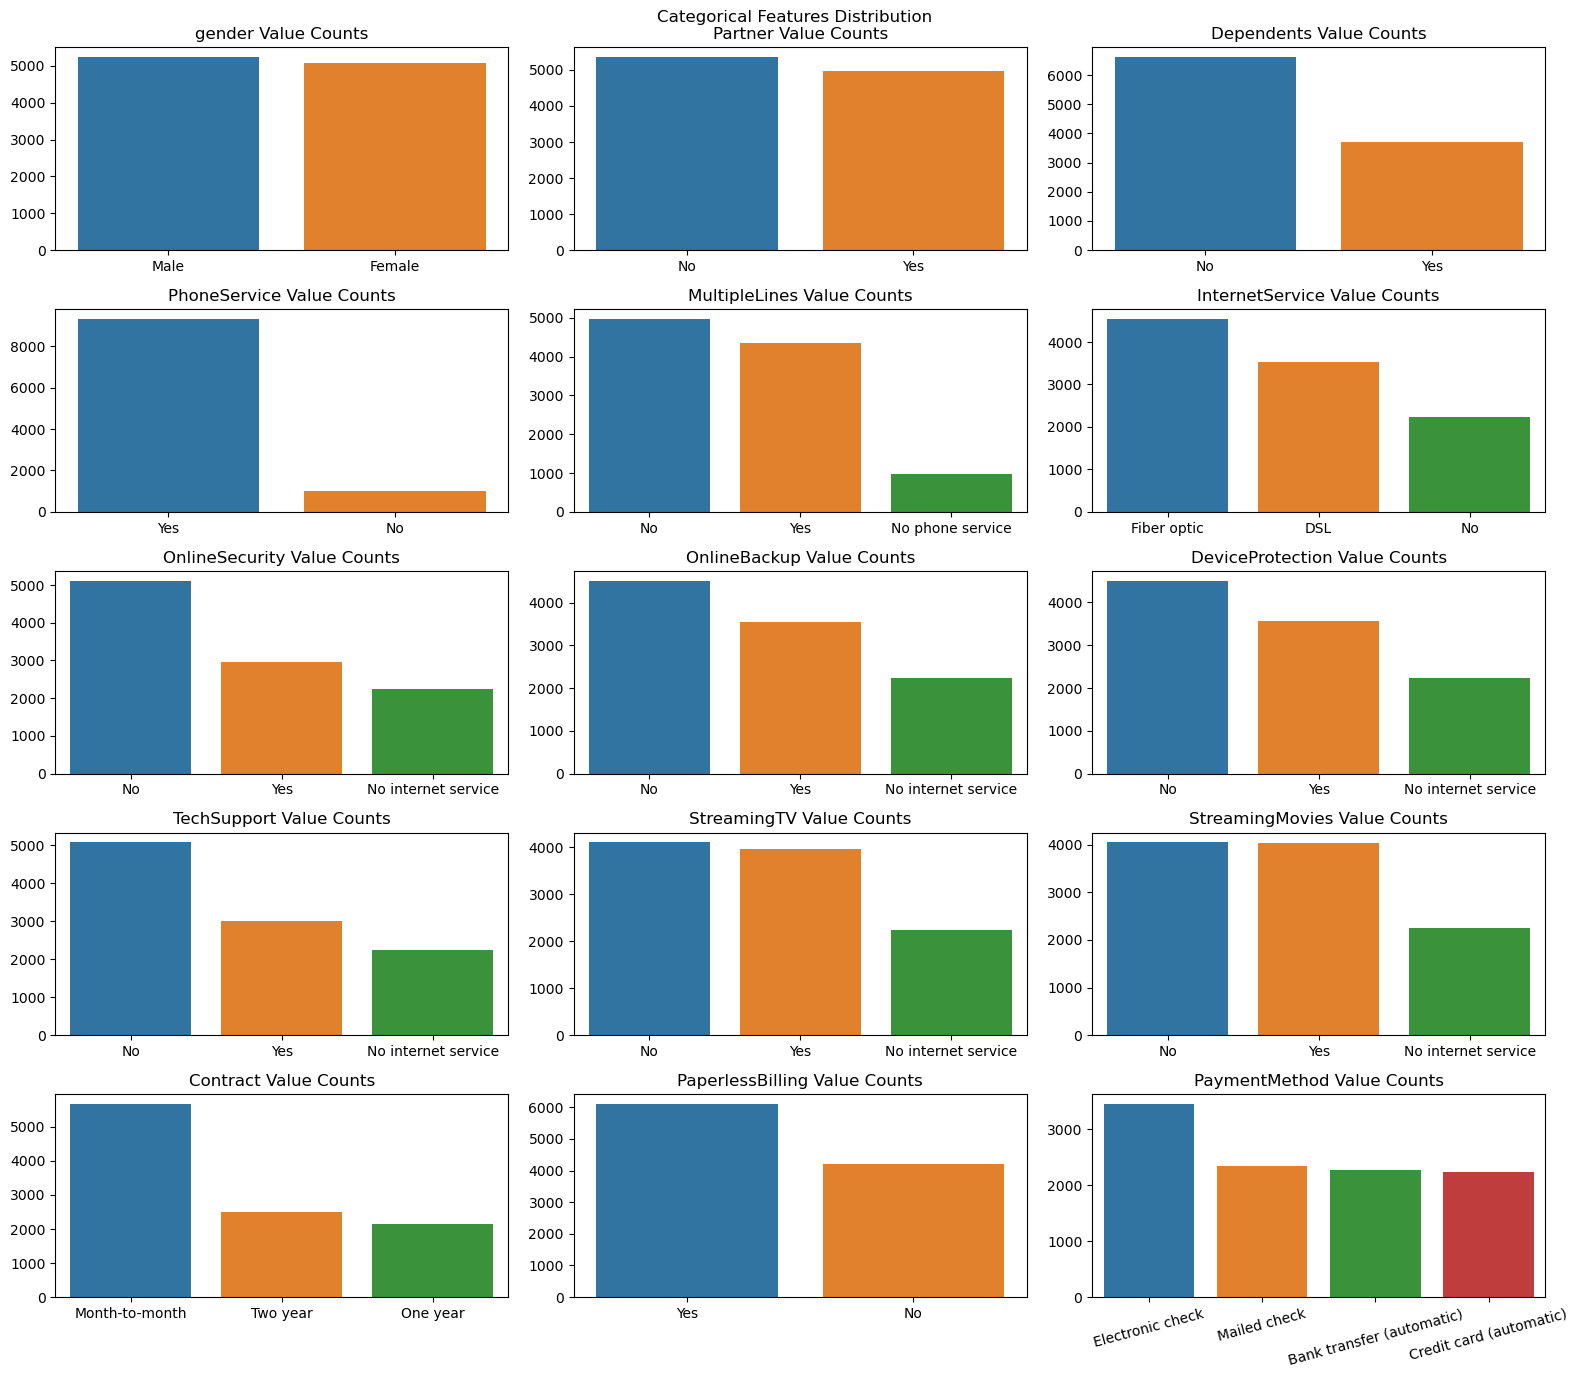

In [25]:
fig = plt.figure(figsize=(16,14))
fig.suptitle("Categorical Features Distribution")

for index, column in enumerate(df.select_dtypes(include='object').drop(columns=['customerID', 'Churn']).columns, start=1):
    df_plot = df[column].value_counts().to_frame().reset_index()

    ax = fig.add_subplot(5, 3, index)
    sns.barplot(data=df_plot, x=column, y='count', ax=ax)
    ax.set_title(f"{column} Value Counts")
    ax.set_xlabel("")
    ax.set_ylabel("")

    if column == 'PaymentMethod':
        ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

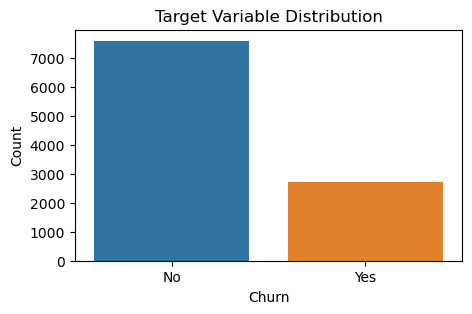

In [26]:
df_plot = df['Churn'].value_counts().to_frame().reset_index()

plt.figure(figsize=(5,3))
sns.barplot(data=df_plot, x='Churn', y='count')
plt.title("Target Variable Distribution")
plt.ylabel("Count")
plt.show()